<a href="https://colab.research.google.com/github/Divyasharma1910/Image_processing/blob/main/Assignment_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import files

uploaded = files.upload()


Saving space.jpg to space.jpg


Enter odd filter size (e.g. 3 or 5): 3
Enter padding method (zero/replication): replication
Enter Gaussian sigma (e.g. 1.0): 1.0


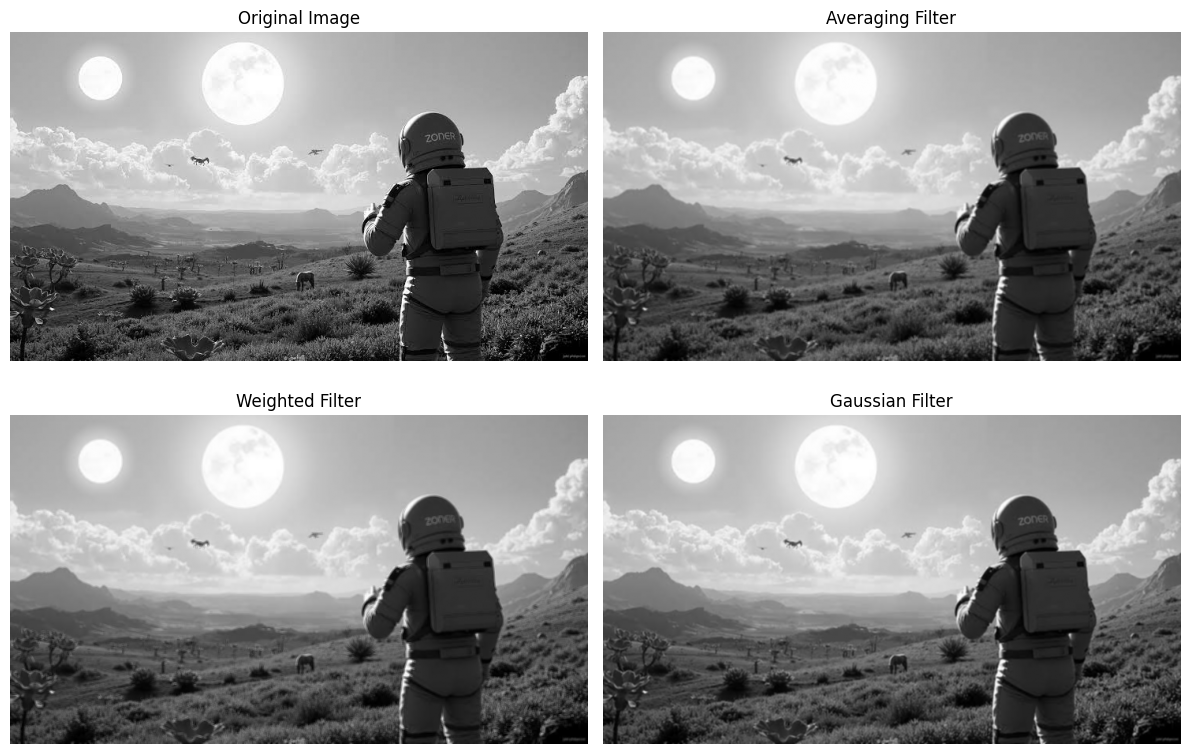

All three filters applied successfully.


In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Read uploaded image in grayscale
filename = list(uploaded.keys())[0]
data = np.frombuffer(uploaded[filename], np.uint8)
img = cv2.imdecode(data, cv2.IMREAD_GRAYSCALE)

if img is None:
    raise ValueError("Unable to read the image.")

# Take input parameters
size = int(input("Enter odd filter size (e.g. 3 or 5): "))
if size < 1 or size % 2 == 0:
    raise ValueError("Filter size must be a positive odd number.")

padding = input(
    "Enter padding method (zero/replication): "
).strip().lower()

if padding not in ["zero", "replication"]:
    raise ValueError("Choose zero or replication.")

sigma = float(input("Enter Gaussian sigma (e.g. 1.0): "))
if sigma <= 0:
    raise ValueError("Sigma must be positive.")

# Apply user-selected padding
p = size // 2

if padding == "zero":
    padded = cv2.copyMakeBorder(
        img, p, p, p, p, cv2.BORDER_CONSTANT, value=0
    )
else:
    padded = cv2.copyMakeBorder(
        img, p, p, p, p, cv2.BORDER_REPLICATE
    )

# 1. Unweighted averaging filter
average_kernel = np.ones((size, size), dtype=np.float32)
average_kernel /= size * size

# 2. Weighted filter: h(x,y) = max(|x|, |y|)
coords = np.arange(size) - p
X, Y = np.meshgrid(coords, coords)
weighted_kernel = np.maximum(np.abs(X), np.abs(Y)).astype(np.float32)

if weighted_kernel.sum() == 0:
    weighted_kernel[p, p] = 1

weighted_kernel /= weighted_kernel.sum()

# 3. Gaussian filter
g = cv2.getGaussianKernel(size, sigma)
gaussian_kernel = g @ g.T

# Filtering and crop to original image dimensions
def apply_filter(kernel):
    result = cv2.filter2D(
        padded, cv2.CV_32F, kernel,
        borderType=cv2.BORDER_CONSTANT
    )
    result = result[p:p + img.shape[0], p:p + img.shape[1]]
    return np.clip(result, 0, 255).astype(np.uint8)

average_img = apply_filter(average_kernel)
weighted_img = apply_filter(weighted_kernel)
gaussian_img = apply_filter(gaussian_kernel)

# Display results
plt.figure(figsize=(12, 8))

images = [
    (img, "Original Image"),
    (average_img, "Averaging Filter"),
    (weighted_img, "Weighted Filter"),
    (gaussian_img, "Gaussian Filter")
]

for i, (image, title) in enumerate(images, 1):
    plt.subplot(2, 2, i)
    plt.imshow(image, cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

# Save results
cv2.imwrite("averaging_filter.png", average_img)
cv2.imwrite("weighted_filter.png", weighted_img)
cv2.imwrite("gaussian_filter.png", gaussian_img)

print("All three filters applied successfully.")
